### Obtaining the GVI

In [ ]:
import sys
sys.path.append("/Users/legariapena.j/Documents/alivestreets-local-copy/alivestreets")

from alivestreets.features.gvi_feature import GVIFeatureExtractor

gvi_extractor = GVIFeatureExtractor()
gvi_extractor.download_model()


Model downloaded.
Vegetation class ID: 12


In [ ]:
from pathlib import Path
import os
PATH_IMAGES = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_03_imagery_quality_assessment/images"

PATH_FOOTPRINTS = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_03_imagery_quality_assessment/boston_buildings_study_area.geojson"

import geopandas as gpd

gdf_boston_area = gpd.read_file(PATH_FOOTPRINTS)
n_buildings = len(gdf_boston_area)
print(f"There are {n_buildings} buildings in the study area.")

image_paths = []
for i in range(0, n_buildings):
    full_path = Path(PATH_IMAGES)/f"building_{i}/image.jpg"
    if(os.path.exists(full_path)):
        image_paths.append(full_path)
    else:
        print("No path could be found")
        image_paths.append(None)

print(f"The number of valid buildings is {len([x for x in image_paths if x is not None])}")

There are 2456 buildings in the study area.
No path could be found
No path could be found
No path could be found
No path could be found
No path could be found
No path could be found
No path could be found
No path could be found
The number of valid buildings is 2448


In [16]:
import numpy as np
from PIL import Image
from tqdm import tqdm
gvi_values = []

for i in tqdm(range(0,len(image_paths))):
    image_path = image_paths[i]
    if(image_path is not None and os.path.exists(image_path)):
        image = np.array(Image.open(image_path))
        results = gvi_extractor.compute(image)
        gvi_values.append(results)

    else:
        gvi_values.append(None)

100%|██████████| 2456/2456 [08:12<00:00,  4.99it/s]


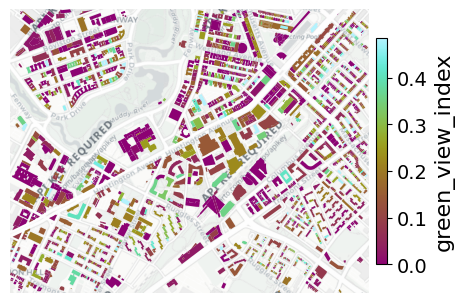

In [31]:
#We can tag the GVI of the buildings to the GDF. It should be quite easy to do. 
gdf_boston_area["green_view_index"] = [x["GVI"] if x is not None else None for x in gvi_values]
from imageable.visualization.footprints_2d import display_footprints_continuous
import cmcrameri.cm as cmc
display_footprints_continuous(
    gdf_boston_area,
    column = "green_view_index",
    cmap = cmc.hawaii,
    add_basemap = True, 
    base_alpha = 0.5,
    min_quantile = 0.05,
    max_quantile = 0.95,
    buffer_meters = 0,
    width = 5, 
    height = 5
    
)


In [ ]:
#Export the footprints
PATH_PARENT_DATA = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_26_gvi_calculations"
export_path = Path(PATH_PARENT_DATA)/f"boston_buildings_with_gvi.geojson"
gdf_boston_area.to_file(export_path, driver = "GeoJSON")


In [22]:
gdf_boston_area

,OBJECTID,PART_USE,PART_BRA_U,GRND_ELEV_2010,ROOF_ELEV_2010,BLDG_HGT_2010,IEL_TYPE,Land_Use,BRA_Land_Use,Added,Shape_Length,Shape_Area,shape_wkt,geometry,green_view_index
0,422,C,C,12.00,25.615,13.615,BLDG,C,C,NaN,0.000836,2.606018e-08,NaN,"POLYGON ((-71.09827 42.34483, -71.09841 42.344...","{'GVI': 0.0, 'confidences': [], 'mask': [[0, 0..."
1,423,C,C,8.00,49.410,41.410,BLDG,C,C,NaN,0.001201,7.536398e-08,NaN,"POLYGON ((-71.09979 42.34566, -71.09993 42.345...","{'GVI': 0.02841552734375, 'confidences': [0.97..."
2,424,A,A,8.00,56.990,48.990,BLDG,A,A,NaN,0.001082,4.282650e-08,NaN,"POLYGON ((-71.08957 42.34476, -71.08957 42.344...","{'GVI': 0.1000244140625, 'confidences': [0.971..."
3,425,E,XG,8.00,32.360,24.360,BLDG,XG,XG,NaN,0.001415,9.175381e-08,NaN,"POLYGON ((-71.0912 42.34432, -71.09126 42.3443...","{'GVI': 0.094140625, 'confidences': [0.9657232..."
4,426,E,XG,6.00,22.680,16.680,BLDG,XG,XG,NaN,0.000571,1.952804e-08,MULTIPOLYGON ZM (((-71.091375939999978 42.3442...,"POLYGON ((-71.09138 42.34423, -71.09149 42.344...","{'GVI': 0.10180908203125, 'confidences': [0.98..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2451,128527,NaN,NaN,11.31,55.170,43.860,BLDG,A,A,1.626394e+12,0.001008,4.796273e-08,NaN,"POLYGON ((-71.08667 42.3348, -71.08661 42.3347...","{'GVI': 0.1741748046875, 'confidences': [0.978..."
2452,128528,NaN,NaN,11.93,65.480,53.550,BLDG,A,A,1.626394e+12,0.002625,1.508386e-07,NaN,"POLYGON ((-71.0858 42.33456, -71.08567 42.3345...","{'GVI': 0.10250244140625, 'confidences': [0.95..."
2453,128529,NaN,NaN,9.39,39.790,30.400,BLDG,E,E,1.626394e+12,0.001698,1.365111e-07,NaN,"POLYGON ((-71.08463 42.33305, -71.08486 42.332...","{'GVI': 0.19064697265625, 'confidences': [0.95..."
2454,128538,NaN,NaN,NaN,NaN,NaN,NaN,E,E,1.687219e+12,0.002645,4.167026e-07,NaN,"POLYGON ((-71.08777 42.33666, -71.08776 42.336...","{'GVI': 0.08605224609375, 'confidences': [0.96..."
